# QKIDS: Training and Evaluation
## Step 2: Quantum Kernel Training & Classical Baselines

This notebook:
- Performs qubit ablation study (4-8 qubits)
- Trains quantum kernel SVM for each qubit count
- Trains classical baselines (Linear, RBF, Polynomial SVM)
- Compares performance and selects optimal configuration
- Saves best model for deployment

In [2]:
!pip install tqdm

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pickle
import joblib
from preprocessing import NSLKDDPreprocessor
from quantum_kernel import create_quantum_kernel
from classical_baselines import create_classical_baseline, create_quantum_svm
from evaluation import (
    evaluate_model, plot_confusion_matrix, compare_models,
    plot_model_comparison, plot_qubit_ablation, plot_kernel_heatmap,
    save_results_to_csv, create_results_summary, print_classification_report
)
from utils import set_seed, print_section, print_subsection

# Set random seed
set_seed(42)

import warnings
warnings.filterwarnings('ignore')

✅ Random seed set to 42


## Configuration

In [2]:
QUBIT_COUNTS = [4, 5, 6, 7, 8]
ENTANGLEMENT = 'linear'  # Linear CNOT chain

## Part 1: Qubit Ablation Study
### Test quantum kernels with 4-8 qubits to find optimal configuration

In [3]:
print_section("QUBIT ABLATION STUDY")

qubit_results = []
quantum_models = {}

for n_qubits QUBIT_COUNTS:
    print_subsection(f"Testing {n_qubits} Qubits")
    
    # Load preprocessed data
    preprocessor = NSLKDDPreprocessor(
        train_path='', test_path='',  # Not needed for loading
        sample_size=1000
    )
    data = preprocessor.load_preprocessed_data(f'preprocessed_{n_qubits}qubits.pkl')
    
    X_train = data['X_train']
    X_test = data['X_test']
    y_train = data['y_train']
    y_test = data['y_test']
    
    print(f"\n   Data loaded: {len(X_train)} train, {len(X_test)} test samples")
    
    # Create quantum kernel
    qkernel = create_quantum_kernel(n_qubits, ENTANGLEMENT)
    
    # Compute kernel matrices
    print("\n   Computing training kernel matrix...")
    K_train = qkernel.compute_kernel_matrix(X_train)
    
    print("\n   Computing test kernel matrix...")
    K_test = qkernel.compute_kernel_matrix(X_test, X_train)
    
    # Train quantum SVM
    qsvm = create_quantum_svm()
    train_metrics = qsvm.train(K_train, y_train, X_train)
    
    # Predict
    y_pred = qsvm.predict(K_test)
    
    # Evaluate
    metrics = evaluate_model(y_test, y_pred, f"Quantum ({n_qubits} qubits)")
    metrics['n_qubits'] = n_qubits
    metrics['training_time'] = train_metrics['training_time']
    
    qubit_results.append(metrics)
    quantum_models[n_qubits] = {
        'model': qsvm,
        'kernel': qkernel,
        'data': data,
        'K_train': K_train,
        'K_test': K_test
    }
    
    print(f"\n✅ {n_qubits} qubits complete!\n")


  QUBIT ABLATION STUDY


────────────────────────────────────────────────────────────
  Testing 4 Qubits
────────────────────────────────────────────────────────────

📂 Loaded preprocessed data from data\preprocessed_4qubits.pkl

   Data loaded: 800 train, 200 test samples
🔮 Quantum Kernel initialized:
   Qubits: 4
   Entanglement: linear
   Device: default.qubit

   Computing training kernel matrix...

⚛️  Computing quantum kernel matrix (800×800)...


   Kernel computation: 100%|██████████████████████████████████████████████████████████████████████████████████████| 320400/320400 [26:37<00:00, 200.55it/s]


   ✓ Kernel matrix computed: (800, 800)
   ✓ Min value: 0.0000, Max value: 1.0000

   Computing test kernel matrix...

⚛️  Computing quantum kernel matrix (200×800)...


   Kernel computation: 100%|██████████████████████████████████████████████████████████████████████████████████████| 160000/160000 [13:01<00:00, 204.71it/s]


   ✓ Kernel matrix computed: (200, 800)
   ✓ Min value: 0.0000, Max value: 1.0000
🔮 Quantum Kernel SVM initialized

🎯 Training Quantum Kernel SVM...
   ✓ Training complete in 0.01s
   ✓ Support vectors: 237

📊 Evaluating Quantum (4 qubits)...
   Accuracy:  0.7450
   Precision: 0.6690
   Recall:    0.9700
   F1-Score:  0.7918

✅ 4 qubits complete!


────────────────────────────────────────────────────────────
  Testing 5 Qubits
────────────────────────────────────────────────────────────

📂 Loaded preprocessed data from data\preprocessed_5qubits.pkl

   Data loaded: 800 train, 200 test samples
🔮 Quantum Kernel initialized:
   Qubits: 5
   Entanglement: linear
   Device: default.qubit

   Computing training kernel matrix...

⚛️  Computing quantum kernel matrix (800×800)...


...

   ✓ Kernel matrix computed: (200, 800)
   ✓ Min value: 0.0000, Max value: 1.0000
🔮 Quantum Kernel SVM initialized

🎯 Training Quantum Kernel SVM...
   ✓ Training complete in 0.00s
   ✓ Support vectors: 207

📊 Evaluating Quantum (7 qubits)...
   Accuracy:  0.7450
   Precision: 0.6623
   Recall:    1.0000
   F1-Score:  0.7968

✅ 7 qubits complete!


────────────────────────────────────────────────────────────
  Testing 8 Qubits
────────────────────────────────────────────────────────────

📂 Loaded preprocessed data from data\preprocessed_8qubits.pkl

   Data loaded: 800 train, 200 test samples
🔮 Quantum Kernel initialized:
   Qubits: 8
   Entanglement: linear
   Device: default.qubit

   Computing training kernel matrix...

⚛️  Computing quantum kernel matrix (800×800)...


   Kernel computation: 100%|██████████████████████████████████████████████████████████████████████████████████████| 320400/320400 [48:52<00:00, 109.25it/s]


   ✓ Kernel matrix computed: (800, 800)
   ✓ Min value: 0.0000, Max value: 1.0000

   Computing test kernel matrix...

⚛️  Computing quantum kernel matrix (200×800)...


   Kernel computation: 100%|██████████████████████████████████████████████████████████████████████████████████████| 160000/160000 [24:02<00:00, 110.95it/s]

   ✓ Kernel matrix computed: (200, 800)
   ✓ Min value: 0.0000, Max value: 1.0000
🔮 Quantum Kernel SVM initialized

🎯 Training Quantum Kernel SVM...
   ✓ Training complete in 0.01s
   ✓ Support vectors: 181

📊 Evaluating Quantum (8 qubits)...
   Accuracy:  0.7700
   Precision: 0.6985
   Recall:    0.9500
   F1-Score:  0.8051

✅ 8 qubits complete!



### Visualize Qubit Ablation Results

In [5]:
import os

# Create results directories
os.makedirs('../results/figures', exist_ok=True)
os.makedirs('../results/metrics', exist_ok=True)

print("✅ Results directories created!")

✅ Results directories created!



  QUBIT ABLATION RESULTS

   💾 Qubit ablation plot saved to ../results/figures/qubit_ablation.png


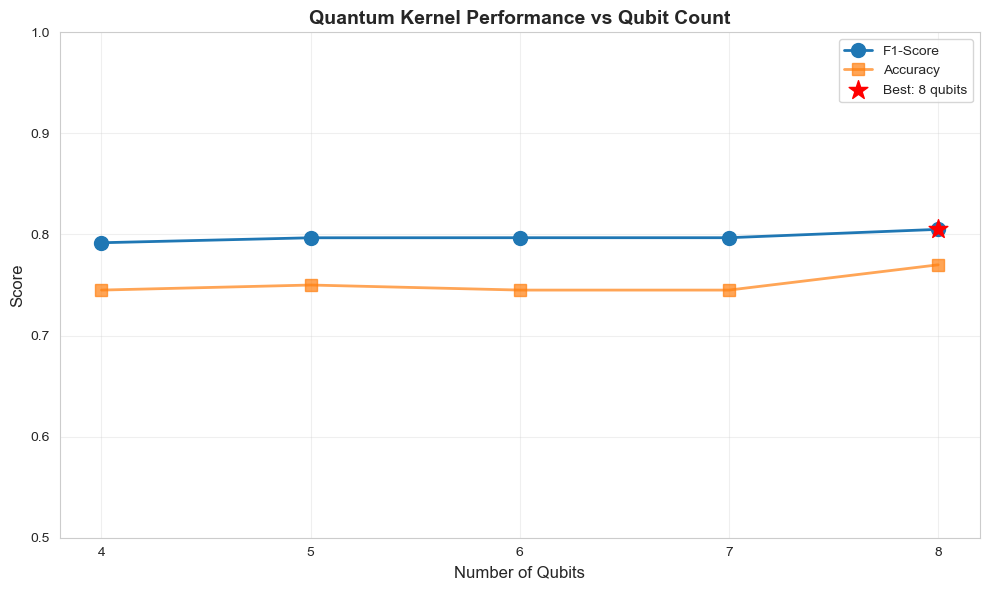


🎯 OPTIMAL CONFIGURATION: 8 qubits (F1=0.8051)


In [6]:
print_section("QUBIT ABLATION RESULTS")

# Plot performance vs qubits
best_qubits, best_f1 = plot_qubit_ablation(
    qubit_results,
    save_path='../results/figures/qubit_ablation.png'
)

print(f"\n🎯 OPTIMAL CONFIGURATION: {best_qubits} qubits (F1={best_f1:.4f})")

## Part 2: Classical Baselines
### Train classical SVMs using the optimal number of features

In [7]:
print_section("TRAINING CLASSICAL BASELINES")

# Use optimal qubit count's data
optimal_data = quantum_models[best_qubits]['data']
X_train = optimal_data['X_train']
X_test = optimal_data['X_test']
y_train = optimal_data['y_train']
y_test = optimal_data['y_test']

classical_results = []

# Linear SVM
print_subsection("Linear SVM")
linear_svm = create_classical_baseline('linear', tune=False)
linear_svm.train(X_train, y_train)
y_pred_linear = linear_svm.predict(X_test)
metrics_linear = evaluate_model(y_test, y_pred_linear, "Linear SVM")
classical_results.append(metrics_linear)

# RBF SVM (with tuning)
print_subsection("RBF SVM (with hyperparameter tuning)")
rbf_svm = create_classical_baseline('rbf', tune=True)
rbf_svm.train(X_train, y_train)
y_pred_rbf = rbf_svm.predict(X_test)
metrics_rbf = evaluate_model(y_test, y_pred_rbf, "RBF SVM")
classical_results.append(metrics_rbf)

# Polynomial SVM
print_subsection("Polynomial SVM")
poly_svm = create_classical_baseline('poly', tune=True)
poly_svm.train(X_train, y_train)
y_pred_poly = poly_svm.predict(X_test)
metrics_poly = evaluate_model(y_test, y_pred_poly, "Polynomial SVM")
classical_results.append(metrics_poly)

print("\n✅ Classical baselines training complete!")


  TRAINING CLASSICAL BASELINES


────────────────────────────────────────────────────────────
  Linear SVM
────────────────────────────────────────────────────────────
🔧 Classical SVM initialized:
   Kernel: linear
   Hyperparameter tuning: False

🎯 Training LINEAR SVM...
   ✓ Training complete in 0.05s

📊 Evaluating Linear SVM...
   Accuracy:  0.7650
   Precision: 0.6879
   Recall:    0.9700
   F1-Score:  0.8050

────────────────────────────────────────────────────────────
  RBF SVM (with hyperparameter tuning)
────────────────────────────────────────────────────────────
🔧 Classical SVM initialized:
   Kernel: rbf
   Hyperparameter tuning: True

🎯 Training RBF SVM...
   Tuning hyperparameters...
   ✓ Best parameters: {'C': 10, 'gamma': 'auto'}
   ✓ Training complete in 22.10s

📊 Evaluating RBF SVM...
   Accuracy:  0.7650
   Precision: 0.6934
   Recall:    0.9500
   F1-Score:  0.8017

────────────────────────────────────────────────────────────
  Polynomial SVM
───────────────────────

## Part 3: Comprehensive Comparison


  FINAL MODEL COMPARISON


📊 Model Comparison
                    model  accuracy  precision  recall  f1_score  n_qubits  training_time
               Linear SVM     0.765   0.687943    0.97  0.804979       NaN            NaN
                  RBF SVM     0.765   0.693431    0.95  0.801688       NaN            NaN
           Polynomial SVM     0.775   0.703704    0.95  0.808511       NaN            NaN
Quantum Kernel (8 qubits)     0.770   0.698529    0.95  0.805085       8.0       0.005096
   💾 Comparison plot saved to ../results/figures/model_comparison.png


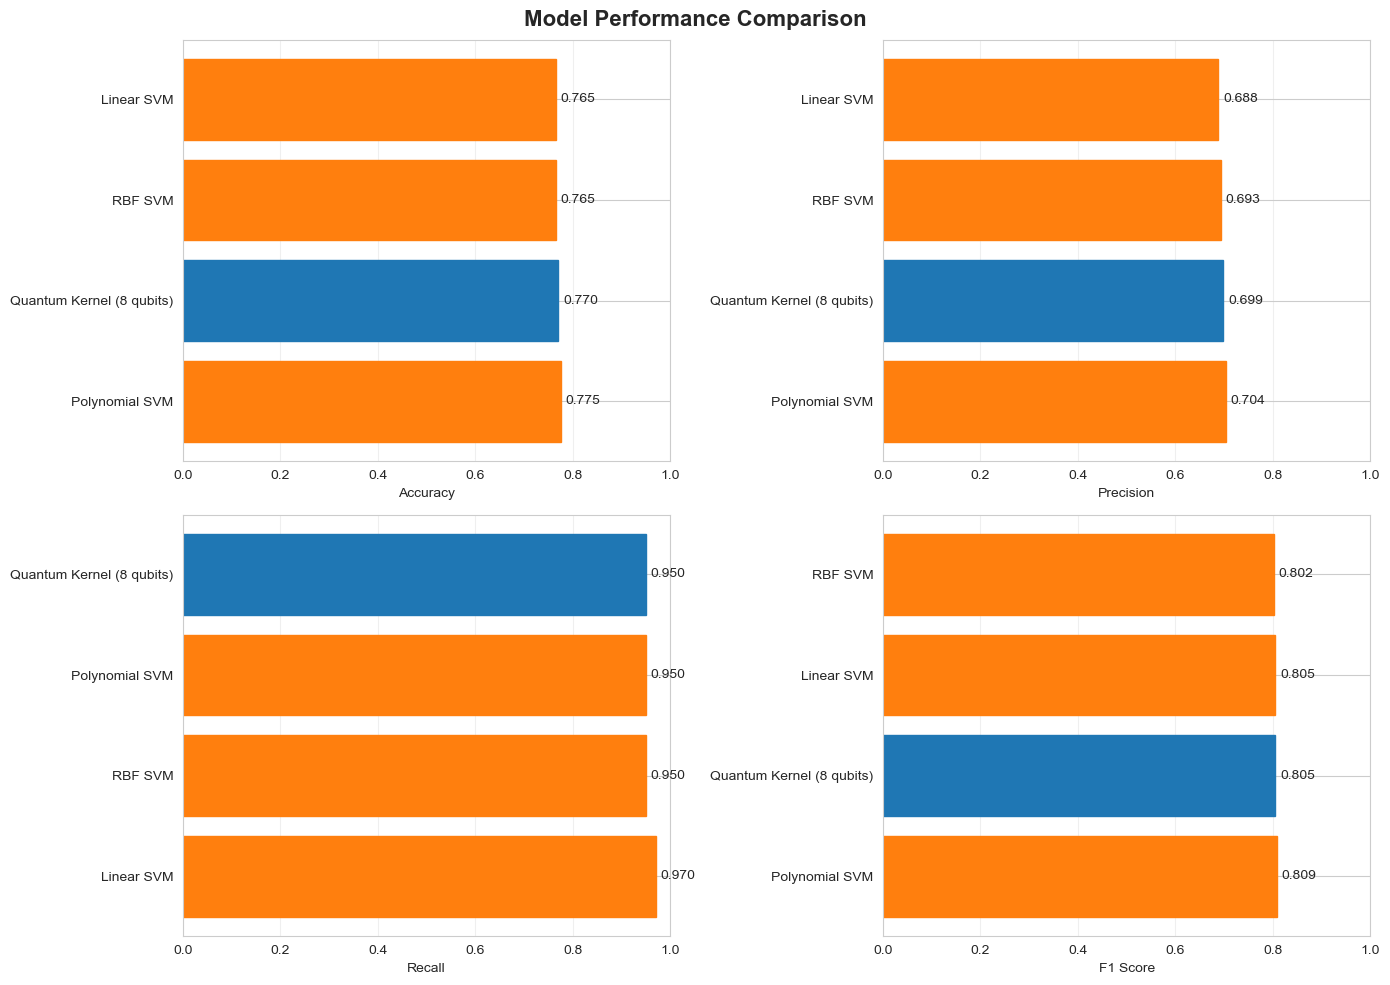


💾 Results saved to results\metrics\model_comparison.csv


In [8]:
print_section("FINAL MODEL COMPARISON")

# Get quantum results for optimal qubit count
optimal_quantum_result = [r for r in qubit_results if r['n_qubits'] == best_qubits][0]
optimal_quantum_result['model'] = f"Quantum Kernel ({best_qubits} qubits)"

# Combine all results
all_results = classical_results + [optimal_quantum_result]

# Compare
comparison_df = compare_models(all_results)

# Plot comparison
plot_model_comparison(
    comparison_df,
    save_path='../results/figures/model_comparison.png'
)

# Save results
save_results_to_csv(comparison_df, 'model_comparison.csv')

## Part 4: Detailed Analysis


  DETAILED ANALYSIS


1️⃣  Quantum Kernel Confusion Matrix
   💾 Confusion matrix saved to ../results/figures/quantum_confusion_matrix.png


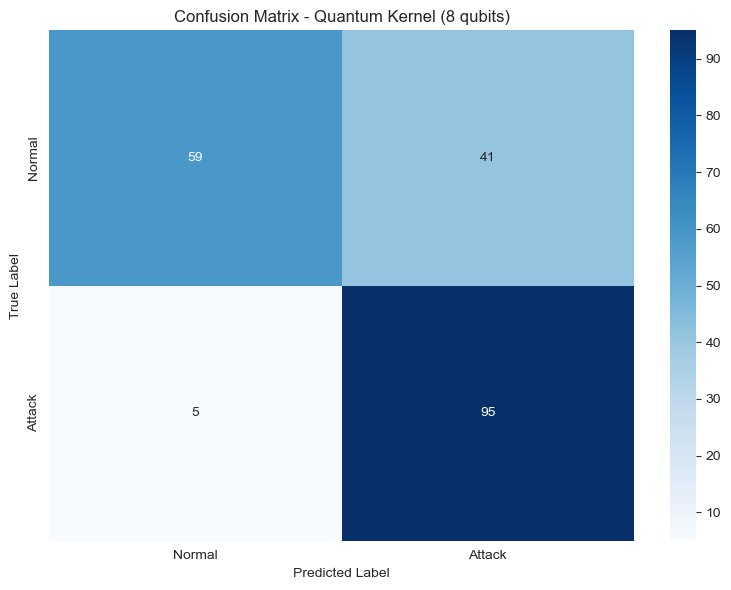


2️⃣  RBF SVM Confusion Matrix
   💾 Confusion matrix saved to ../results/figures/rbf_confusion_matrix.png


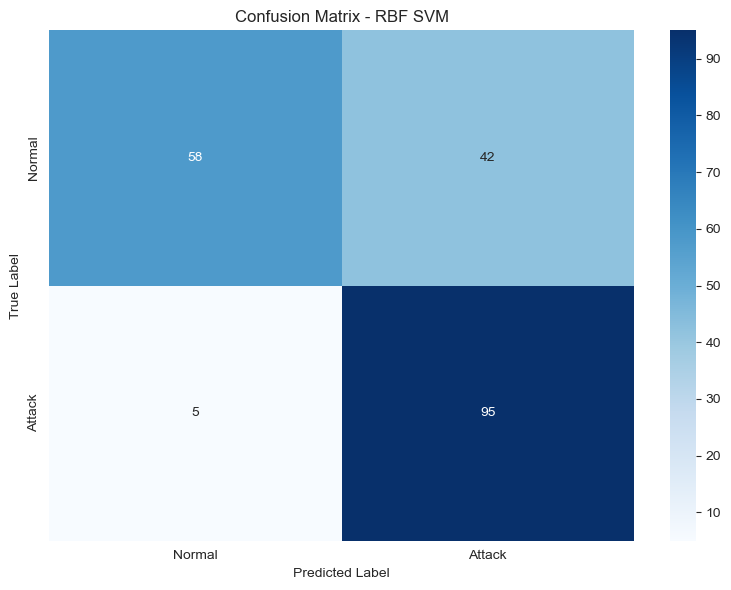


📋 Classification Report - Quantum (8 qubits)
              precision    recall  f1-score   support

      Normal       0.92      0.59      0.72       100
      Attack       0.70      0.95      0.81       100

    accuracy                           0.77       200
   macro avg       0.81      0.77      0.76       200
weighted avg       0.81      0.77      0.76       200


📋 Classification Report - RBF SVM
              precision    recall  f1-score   support

      Normal       0.92      0.58      0.71       100
      Attack       0.69      0.95      0.80       100

    accuracy                           0.77       200
   macro avg       0.81      0.76      0.76       200
weighted avg       0.81      0.77      0.76       200



In [9]:
print_section("DETAILED ANALYSIS")

# Confusion matrices for top performers
print("\n1️⃣  Quantum Kernel Confusion Matrix")
qsvm_optimal = quantum_models[best_qubits]['model']
K_test_optimal = quantum_models[best_qubits]['K_test']
y_pred_quantum = qsvm_optimal.predict(K_test_optimal)

plot_confusion_matrix(
    y_test, y_pred_quantum,
    f"Quantum Kernel ({best_qubits} qubits)",
    save_path='../results/figures/quantum_confusion_matrix.png'
)

print("\n2️⃣  RBF SVM Confusion Matrix")
plot_confusion_matrix(
    y_test, y_pred_rbf,
    "RBF SVM",
    save_path='../results/figures/rbf_confusion_matrix.png'
)

# Classification reports
print_classification_report(y_test, y_pred_quantum, f"Quantum ({best_qubits} qubits)")
print_classification_report(y_test, y_pred_rbf, "RBF SVM")

## Part 5: Visualize Quantum Kernel


  QUANTUM KERNEL VISUALIZATION

   💾 Kernel heatmap saved to ../results/figures/quantum_kernel_heatmap.png


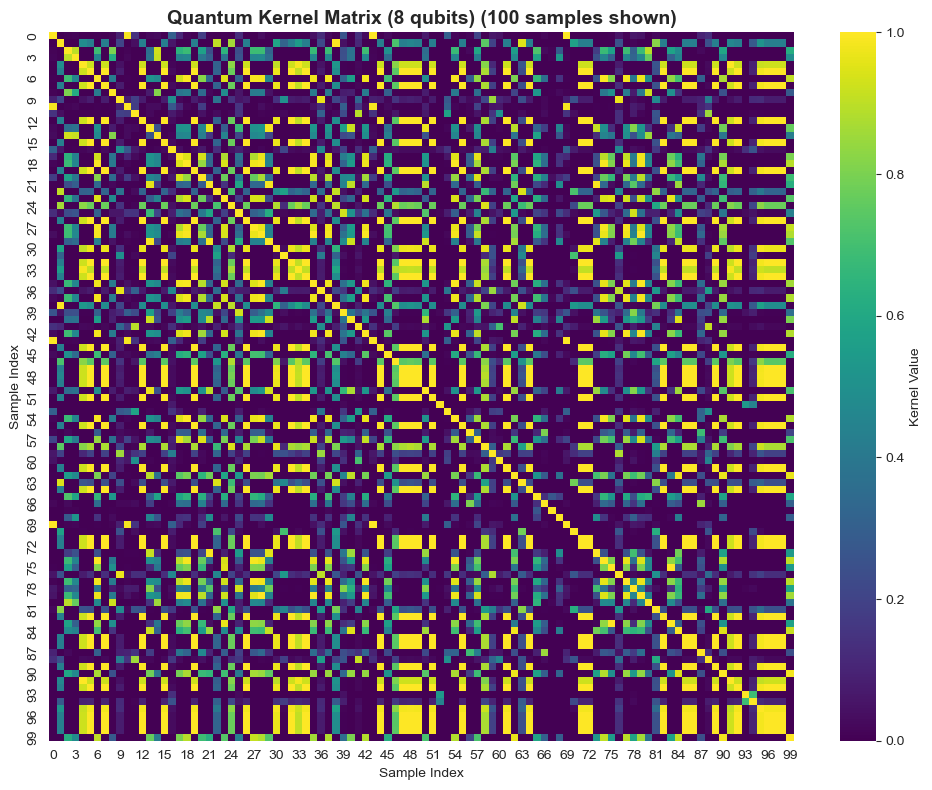

In [10]:
print_section("QUANTUM KERNEL VISUALIZATION")

K_train_optimal = quantum_models[best_qubits]['K_train']

plot_kernel_heatmap(
    K_train_optimal,
    f"Quantum Kernel Matrix ({best_qubits} qubits)",
    save_path='../results/figures/quantum_kernel_heatmap.png'
)

## Part 6: Save Best Model

In [12]:
import os

# Create saved_models directory
os.makedirs('../saved_models', exist_ok=True)

print("✅ saved_models directory created!")

✅ saved_models directory created!


In [13]:
print_section("SAVING BEST MODEL")

# Save quantum model
model_package = {
    'quantum_svm': qsvm_optimal,
    'quantum_kernel': quantum_models[best_qubits]['kernel'],
    'n_qubits': best_qubits,
    'selected_features': optimal_data['selected_features'],
    'X_train': X_train,
    'y_train': y_train,
    'scaler': None,  # Will be added if needed
    'performance': optimal_quantum_result
}

joblib.dump(model_package, '../saved_models/best_quantum_model.pkl')
print("✅ Quantum model saved: ../saved_models/best_quantum_model.pkl")

# Save classical baseline (RBF)
classical_package = {
    'model': rbf_svm,
    'model_type': 'rbf_svm',
    'selected_features': optimal_data['selected_features'],
    'performance': metrics_rbf
}

joblib.dump(classical_package, '../saved_models/best_classical_model.pkl')
print("✅ Classical model saved: ../saved_models/best_classical_model.pkl")


  SAVING BEST MODEL

✅ Quantum model saved: ../saved_models/best_quantum_model.pkl
✅ Classical model saved: ../saved_models/best_classical_model.pkl


## Final Summary

In [14]:
summary = create_results_summary(qubit_results, comparison_df, best_qubits)

# Save summary
with open('../results/metrics/experiment_summary.pkl', 'wb') as f:
    pickle.dump(summary, f)

print("\n" + "="*70)
print("  EXPERIMENT COMPLETE!")
print("="*70)
print("\n📊 Results saved in: ../results/")
print("📈 Figures saved in: ../results/figures/")
print("💾 Models saved in: ../saved_models/")
print("\n➡️  Next step: Run notebook 03_interactive_demo.ipynb")


  RESULTS SUMMARY

✨ Best Qubit Count: 8
✨ Best Quantum F1-Score: 0.8051
✨ Best Classical F1-Score: 0.8085

📊 Classical kernels perform better in this setup

  EXPERIMENT COMPLETE!

📊 Results saved in: ../results/
📈 Figures saved in: ../results/figures/
💾 Models saved in: ../saved_models/

➡️  Next step: Run notebook 03_interactive_demo.ipynb
